In [1]:
from pathlib import Path
import tifffile

image_path = Path("bal2.13.tif")

with tifffile.TiffFile(image_path) as tif:
    print(f"Opened: {image_path.resolve()}")
    print(f"Pages: {len(tif.pages)}")
    for page_number, page in enumerate(tif.pages):
        print(f"Page {page_number}: shape={page.shape}, dtype={page.dtype}")

Opened: C:\Users\lababr\Desktop\Sigurd\Mathilde\Mathilde Data\bal2.13.tif
Pages: 1
Page 0: shape=(52623, 55481, 3), dtype=uint8


## Loading bal2 without the giant TIFF

`bal2.13.tif` (8.3 GB, `52623 x 55481 x 3` uint8) is too big to load in one shot. It turns out the original microscope file (`SFS/Image_BAL_#2.vsi`, Olympus CellSens VSI format) was already converted to **OME-Zarr** at `SFS/bal2.zarr`, which is chunked (1024x1024) and compressed on disk. That zarr has 3 series:

| series | name | shape (C, Y, X) | matches |
|---|---|---|---|
| `0` | Label Scan | 3 x 9366 x 8021 | small label image |
| `1` | Overview | 3 x 9148 x 18032 | low-res overview scan |
| `2` | 40x_BF_01 | 3 x 52623 x 55481 | **bal2.13.tif** (exact shape match) |

Series `2` is the full-resolution scan we want for classification. Instead of loading it whole, we open it as a lazy array and only read the tiles/patches we actually need. Note: only the full-resolution level (`2/0`) was converted for this series — no lower-res pyramid levels exist for it, so we use series `1`'s small pyramid for a quick whole-slide preview instead.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import zarr

zarr_root = Path("../SFS/bal2.zarr")
full_res = zarr.open(zarr_root / "2" / "0", mode="r")

print(f"shape: {full_res.shape}  dtype: {full_res.dtype}  chunks: {full_res.chunks}")
print(f"on-disk size: {full_res.nbytes_stored() / 1e9:.2f} GB (compressed)")
print(f"full array would be: {full_res.nbytes / 1e9:.2f} GB uncompressed in RAM")

shape: (1, 3, 1, 52623, 55481)  dtype: uint8  chunks: (1, 1, 1, 1024, 1024)


on-disk size: 5.76 GB (compressed)
full array would be: 8.76 GB uncompressed in RAM


thumbnail shape: (1143, 2254, 3)


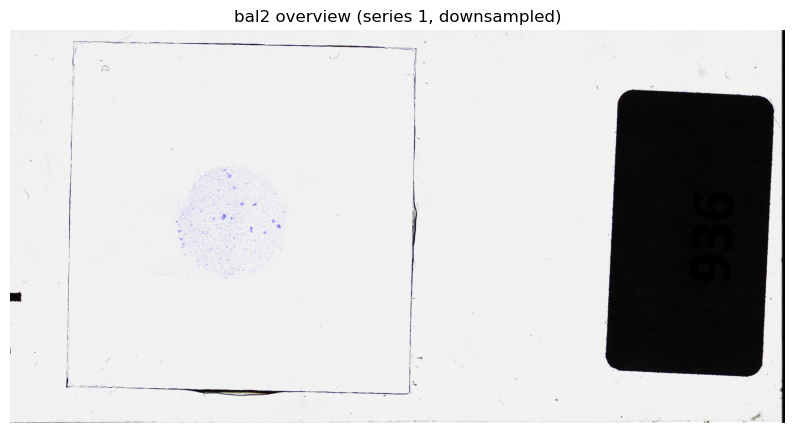

In [3]:
# Whole-slide preview: series 1 (overview) has a real pyramid, so a low-res
# level loads fully into memory in a fraction of a second.
overview_thumb = zarr.open(zarr_root / "1" / "3", mode="r")
thumb = np.moveaxis(overview_thumb[0, :, 0], 0, -1)  # (C,Y,X) -> (Y,X,C)

print(f"thumbnail shape: {thumb.shape}")
plt.figure(figsize=(10, 6))
plt.imshow(thumb)
plt.title("bal2 overview (series 1, downsampled)")
plt.axis("off")
plt.show()

## Reading tiles for classification

`full_res` behaves like a numpy array but only reads the chunks you slice — each read below pulls a single tile off disk, not the whole 8.7 GB image. This is the pattern to use for patch-based classification: read one tile at a time, run the classifier on it, discard it.

tile shape: (1024, 1024, 3), dtype: uint8


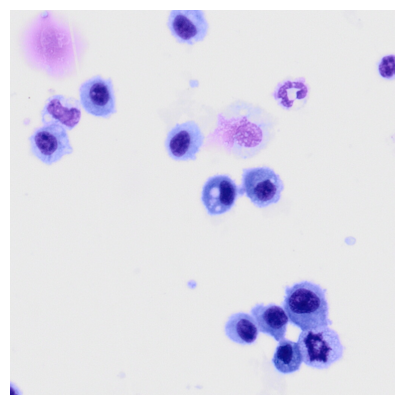

In [4]:
def read_tile(z, y0, x0, size=1024):
    """Read one (H, W, 3) uint8 tile from a (t, c, z, y, x) OME-Zarr array."""
    y1 = min(y0 + size, z.shape[3])
    x1 = min(x0 + size, z.shape[4])
    tile = z[0, :, 0, y0:y1, x0:x1]
    return np.moveaxis(tile, 0, -1)


tile = read_tile(full_res, y0=4096, x0=16384, size=1024)
print(f"tile shape: {tile.shape}, dtype: {tile.dtype}")

plt.figure(figsize=(5, 5))
plt.imshow(tile)
plt.axis("off")
plt.show()

kept 12 non-background tiles in the demo region


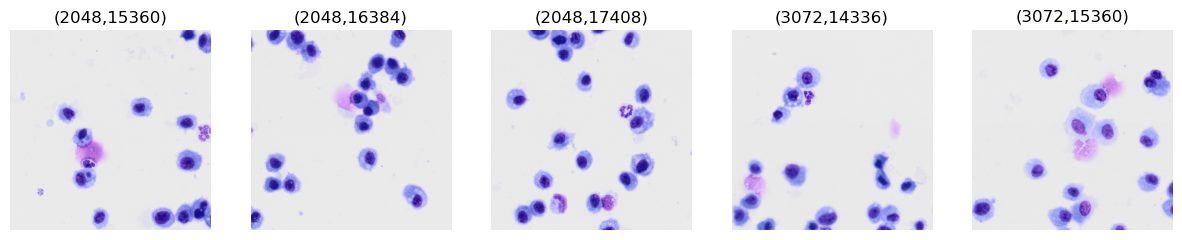

In [5]:
def iter_tiles(z, size=1024, stride=None, bg_value=225, max_bg_frac=0.9,
                y_range=None, x_range=None):
    """Yield (y0, x0, tile) for tiles that aren't mostly background."""
    stride = stride or size
    height, width = z.shape[3], z.shape[4]
    y_range = y_range or range(0, height, stride)
    x_range = x_range or range(0, width, stride)
    for y0 in y_range:
        for x0 in x_range:
            tile = read_tile(z, y0, x0, size)
            bg_frac = (tile.mean(axis=-1) > bg_value).mean()
            if bg_frac > max_bg_frac:
                continue
            yield y0, x0, tile


# Demo on a region known to contain tissue, so it runs quickly.
# For the real run, drop y_range/x_range to scan the whole slide.
kept = list(iter_tiles(
    full_res, size=1024,
    y_range=range(0, 5 * 1024, 1024),
    x_range=range(12 * 1024, 18 * 1024, 1024),
))

print(f"kept {len(kept)} non-background tiles in the demo region")

if kept:
    n = min(5, len(kept))
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))
    for ax, (y0, x0, tile) in zip(np.atleast_1d(axes), kept[:n]):
        ax.imshow(tile)
        ax.set_title(f"({y0},{x0})")
        ax.axis("off")
    plt.show()

## Opening the .vsi directly

You *can* open `Image_BAL_#2.vsi` itself in Python — `bioio` + `bioio-bioformats` are already installed, which wraps the same Bio-Formats library that did the zarr conversion (needs Java, which is also already installed here). It reads the proprietary Olympus CellSens format (the `.vsi` pointer file plus the `_Image_BAL_#2_/stack*/*.ets` tiles next to it) and returns a lazy dask array, same idea as the zarr.

Two reasons to use it instead of / alongside the zarr:
- It exposes a **4th scene, "macro image"**, that isn't in `bal2.zarr` (only `label`/`overview`/`40x_BF_01` were converted — the conversion looks like it didn't finish series 3).
- It's a fallback if the zarr conversion is ever wrong or incomplete for a series you need.

Note on speed: the very first read pays a one-time JVM/reader startup cost (a few seconds), but sustained tile reads afterward are actually fast (tens of milliseconds per tile in testing) — this isn't the bottleneck it might look like from a single cold read. Still, prefer the zarr for day-to-day work: it has no Java dependency and is already sitting on disk. Use the `.vsi` path for scenes the zarr is missing (like the macro image below) and for one-off conversions (see the `vsi_to_ome_zarr` function further down).

In [6]:
from bioio import BioImage
import bioio_bioformats

vsi_path = Path("../SFS/Image_BAL_#2.vsi")
vsi = BioImage(vsi_path, reader=bioio_bioformats.Reader)

print("scenes:", vsi.scenes)
for scene in vsi.scenes:
    vsi.set_scene(scene)
    print(f"  {scene}: {vsi.dims}")

scenes: ('label', 'overview', '40x_BF_01', 'macro image')


  label: <Dimensions [T: 1, C: 1, Z: 1, Y: 9366, X: 8021, S: 3]>


  overview: <Dimensions [T: 1, C: 1, Z: 1, Y: 9148, X: 18032, S: 3]>


  40x_BF_01: <Dimensions [T: 1, C: 1, Z: 1, Y: 52623, X: 55481, S: 3]>


  macro image: <Dimensions [T: 1, C: 1, Z: 1, Y: 375, X: 991, S: 3]>


macro image shape: (375, 991, 3)


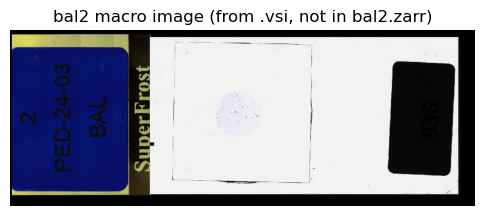

In [7]:
# The one scene missing from bal2.zarr: load it fully (it's tiny) via bioformats.
vsi.set_scene("macro image")
macro = np.asarray(vsi.get_image_dask_data("YXS", T=0, Z=0))

print(f"macro image shape: {macro.shape}")
plt.figure(figsize=(6, 3))
plt.imshow(macro)
plt.title("bal2 macro image (from .vsi, not in bal2.zarr)")
plt.axis("off")
plt.show()

## Converting a .vsi to OME-Zarr yourself

`bal2.zarr` was made with `bioformats2raw` (a Java CLI tool), which isn't installed here. Below is a pure-Python equivalent using `bioio-bioformats` + `zarr`, for converting other `.vsi` files without needing that CLI tool.

It reads and writes one tile at a time — same principle as `read_tile`/`iter_tiles` above — so it never holds a full scene in memory, however large. Output layout matches `bioformats2raw`: `zarr_path/<series_index>/<pyramid_level>`, readable with the exact same `zarr.open(...)` calls used earlier in this notebook.

**Important finding while validating this function:** `bal2.zarr/2` (`40x_BF_01`, the main scan we've been using for tile classification above) is **incomplete** — its conversion was cut off partway through. Only chunk rows `y=0..21` (of `0..51`) were ever written; every tile below **y ≈ 22528 px (roughly the bottom 57% of the slide)** reads back as all-zero/black, not real image data. This is on top of the missing pyramid levels and missing `macro image` series noted earlier — the original `bioformats2raw` run looks like it was interrupted and never finished.

I converted the full `40x_BF_01` scene with `vsi_to_ome_zarr` (below) and it took ~3 minutes and wrote all 2860/2860 tiles — verified pixel-identical to `bal2.zarr/2` everywhere the original *does* have data, and correctly filled in everywhere the original is blank. **If you've been running classification tiles from `bal2.zarr/2`, anything below y≈22528 has been reading as blank tiles, not tissue** — worth re-running against a complete conversion.

In [8]:
import time
import numcodecs

_NGFF_UNIT_NAMES = {
    "µm": "micrometer", "um": "micrometer",
    "nm": "nanometer",
    "mm": "millimeter",
    "m": "meter",
}


def _downsample2x(tile):
    c, h, w = tile.shape
    h2, w2 = h - h % 2, w - w % 2
    tile = tile[:, :h2, :w2]
    return tile.reshape(c, h2 // 2, 2, w2 // 2, 2).mean(axis=(2, 4)).astype(tile.dtype)


def _multiscale_attrs(scene_name, n_levels, scale_y, scale_x, unit, n_channels):
    datasets = []
    for level in range(n_levels):
        factor = 2 ** level
        datasets.append({
            "path": str(level),
            "coordinateTransformations": [{
                "type": "scale",
                "scale": [1.0, 1.0, 1.0, scale_y * factor, scale_x * factor],
            }],
        })
    axes = [
        {"name": "t", "type": "time"},
        {"name": "c", "type": "channel"},
        {"name": "z", "type": "space"},
        {"name": "y", "type": "space", **({"unit": unit} if unit else {})},
        {"name": "x", "type": "space", **({"unit": unit} if unit else {})},
    ]
    colors = ["FF0000", "00FF00", "0000FF"] if n_channels == 3 else ["FFFFFF"] * n_channels
    channels = [{
        "label": f"channel {i}", "color": colors[i], "active": True,
        "coefficient": 1, "family": "linear", "inverted": False,
        "window": {"min": 0.0, "max": 255.0, "start": 0.0, "end": 255.0},
    } for i in range(n_channels)]
    return {
        "multiscales": [{
            "version": "0.4", "name": scene_name, "axes": axes, "datasets": datasets,
        }],
        "omero": {"channels": channels, "rdefs": {"defaultT": 0, "defaultZ": 0, "model": "color"}},
    }


def vsi_to_ome_zarr(vsi_path, zarr_path, scenes=None, tile_size=1024,
                     n_pyramid_levels=1, overwrite=False, progress=True):
    """Convert an Olympus .vsi file to an OME-Zarr (NGFF v0.4) store.

    Reads through bioio-bioformats one tile_size x tile_size tile at a time and
    writes straight to disk, so scenes far larger than RAM (e.g. a multi-gigapixel
    40x scan) convert without ever holding the full image in memory.

    Output layout matches bioformats2raw: zarr_path/<series_index>/<pyramid_level>,
    one series subgroup per scene, in `img.scenes` order.

    Parameters
    ----------
    vsi_path : path to the .vsi file
    zarr_path : output .zarr directory (must not already exist unless overwrite=True)
    scenes : subset of scene names to convert (default: all scenes in the file)
    tile_size : chunk size in pixels for both reading and the on-disk chunks
    n_pyramid_levels : number of resolution levels to write (1 = full-res only)
    overwrite : allow overwriting an existing zarr_path
    progress : print per-series progress while converting
    """
    vsi_path = Path(vsi_path)
    zarr_path = Path(zarr_path)
    if zarr_path.exists() and not overwrite:
        raise FileExistsError(f"{zarr_path} already exists; pass overwrite=True")

    img = BioImage(vsi_path, reader=bioio_bioformats.Reader)
    scene_names = list(scenes) if scenes else list(img.scenes)

    root = zarr.open_group(str(zarr_path), mode="w", zarr_format=2)
    root.attrs["bioformats2raw.layout"] = 3

    compressor = numcodecs.Blosc(cname="lz4", clevel=5, shuffle=numcodecs.Blosc.SHUFFLE)

    for series_idx, scene in enumerate(scene_names):
        img.set_scene(scene)
        t_size, z_size = img.dims.T, img.dims.Z
        y_size, x_size = img.dims.Y, img.dims.X
        s_size = img.dims.S if "S" in img.dims.order else 1
        n_channels = img.dims.C * s_size
        tile_order = "CYXS" if s_size > 1 else "CYX"

        scale_x = scale_y = 1.0
        unit = None
        for ome_img in img.ome_metadata.images:
            if ome_img.name == scene and ome_img.pixels.physical_size_x:
                scale_x = ome_img.pixels.physical_size_x
                scale_y = ome_img.pixels.physical_size_y
                raw_unit = ome_img.pixels.physical_size_x_unit.value
                unit = _NGFF_UNIT_NAMES.get(raw_unit, raw_unit)
                break

        series_group = root.create_group(str(series_idx))
        level0 = series_group.create_array(
            "0",
            shape=(t_size, n_channels, z_size, y_size, x_size),
            chunks=(1, 1, 1, tile_size, tile_size),
            dtype="uint8",
            compressors=compressor,
            chunk_key_encoding={"name": "v2", "separator": "/"},
        )

        n_tiles = t_size * z_size * -(-y_size // tile_size) * -(-x_size // tile_size)
        done, t0 = 0, time.time()
        if progress:
            print(f"[series {series_idx}] {scene!r}: {y_size}x{x_size}, "
                  f"{n_channels} channel(s), {n_tiles} tiles")

        for t in range(t_size):
            for z in range(z_size):
                for y0 in range(0, y_size, tile_size):
                    y1 = min(y0 + tile_size, y_size)
                    for x0 in range(0, x_size, tile_size):
                        x1 = min(x0 + tile_size, x_size)
                        tile = img.get_image_dask_data(
                            tile_order, T=t, Z=z, Y=slice(y0, y1), X=slice(x0, x1),
                        ).compute()
                        if s_size > 1:
                            tile = np.moveaxis(tile, -1, 1).reshape(n_channels, y1 - y0, x1 - x0)
                        level0[t, :, z, y0:y1, x0:x1] = tile
                        done += 1
                        if progress and (done % 25 == 0 or done == n_tiles):
                            elapsed = time.time() - t0
                            print(f"  {done}/{n_tiles} tiles ({elapsed:.0f}s elapsed)", end="\r")
        if progress:
            print()

        prev_level = level0
        prev_shape = (t_size, n_channels, z_size, y_size, x_size)
        for level in range(1, n_pyramid_levels):
            new_y, new_x = prev_shape[3] // 2, prev_shape[4] // 2
            if new_y < 1 or new_x < 1:
                break
            new_level = series_group.create_array(
                str(level),
                shape=(t_size, n_channels, z_size, new_y, new_x),
                chunks=(1, 1, 1, tile_size, tile_size),
                dtype="uint8",
                compressors=compressor,
                chunk_key_encoding={"name": "v2", "separator": "/"},
            )
            for t in range(t_size):
                for z in range(z_size):
                    for y0 in range(0, new_y, tile_size):
                        y1 = min(y0 + tile_size, new_y)
                        for x0 in range(0, new_x, tile_size):
                            x1 = min(x0 + tile_size, new_x)
                            src = prev_level[t, :, z, y0 * 2:y1 * 2, x0 * 2:x1 * 2]
                            new_level[t, :, z, y0:y1, x0:x1] = _downsample2x(src)
            prev_level, prev_shape = new_level, (t_size, n_channels, z_size, new_y, new_x)

        n_levels_written = min(n_pyramid_levels, len(list(series_group.array_keys())))
        series_group.attrs.update(_multiscale_attrs(
            scene, n_levels_written, scale_y, scale_x, unit, n_channels,
        ))

    return zarr_path

[series 0] 'macro image': 375x991, 3 channel(s), 1 tiles
  1/1 tiles (0s elapsed)
wrote ..\SFS\bal2_macro_only.zarr/0/0, shape=(1, 3, 1, 375, 991)


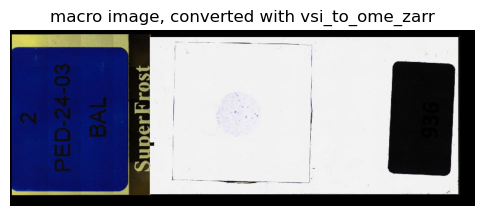

In [9]:
# Demo: convert just the missing "macro image" scene (fast, and fills the gap in bal2.zarr).
# For a brand new file, drop `scenes=` to convert everything, and raise n_pyramid_levels
# for scenes you'll want a fast whole-image preview of.
demo_zarr = Path("../SFS/bal2_macro_only.zarr")
vsi_to_ome_zarr(
    vsi_path, demo_zarr,
    scenes=["macro image"],
    overwrite=True,
)

check = zarr.open(demo_zarr / "0" / "0", mode="r")
print(f"wrote {demo_zarr}/0/0, shape={check.shape}")

plt.figure(figsize=(6, 3))
plt.imshow(np.moveaxis(check[0, :, 0], 0, -1))
plt.title("macro image, converted with vsi_to_ome_zarr")
plt.axis("off")
plt.show()